# NB05 · Recovery and LGD

**Project:** multiyear-credit-engine
**Job requirement covered:** Loss recovery experience.
**Engine module:** `creditengine.models.recovery`
**Assumptions:** A-04, A-13
**Theory:** Altman, Brady, Resti, Sironi (2005); Bluhm §2.4
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

How much is lost when a borrower defaults, how uncertain is that loss, and how much bigger does the tail become if recoveries fall in the same bad years in which defaults rise?

## Results at a glance

| Question | Answer |
|---|---|
| How much is lost per default? | Senior unsecured bonds: mean LGD **60%**, sd 25% — Beta(1.70, 1.14); 12.5% of defaults lose more than 90%. Secured loans: mean 40% |
| Does the cycle link change the long-run LGD? | No — averaged over all years the mean stays exactly 60% for every sensitivity *b* |
| Then why does it matter? | Defaults cluster in bad years, which are now high-LGD years: the LGD actually paid rises to **68%** (*b* = 0.25) or 81% (*b* = 1) on average, and to 81% / 98% in the worst paths |
| Tail impact on the USD 1bn bond book | *b* = 0.25: EL **+14%**, ES 99.5% **+34%**. *b* = 1: EL +35%, ES +67% — the largest single driver of tail loss in the model |
| Which *b* is realistic? | *b* = 1 implies recoveries near 1% in 1991, 2001 and 2009 — far too extreme. *b* = 0.25 gives about 22–24% in those years and 50–57% in good years, a realistic swing |

## Key terms and symbols

| Symbol | Meaning |
|---|---|
| Recovery $R$ | Share of the exposure the lender gets back after a default |
| $LGD = 1 - R$ | Loss given default: share of the exposure lost |
| $m, s$ | Long-run mean and standard deviation of LGD |
| Beta$(\alpha, \beta)$ | Distribution on $[0, 1]$ used for LGD; shape set by $\alpha$ and $\beta$ |
| $Z_t$ | Credit-cycle factor (NB03), low = bad year |
| $b$ | Cycle sensitivity of LGD: 0 = independent of the cycle; larger = worse recoveries in bad years |
| $m(Z)$ | Mean LGD in a year with cycle state $Z$ |

## Inputs

| Data | File | Used for |
|---|---|---|
| LGD settings by asset class (A-04) | declared in section 1 | bond and loan LGD |
| Commercial-mortgage loss severity | NB07 (from the property value, not a beta draw) | comparison |
| Implied cycle factor (NB03) | `data/processed/implied_z.parquet` | recovery vs default rate, 1981–2025 |
| Matrix, thresholds (NB01, NB04) | `data/processed/` | tail-impact run on the NB06 bond book |

A table of observed recoveries by seniority (`data/external/recovery_rates_by_seniority.csv`) is planned for v0.3; until then the LGD levels are declared from the usual published ranges and tested by sensitivity.

## Outputs

- `data/processed/lgd_parameters.yaml` — beta parameters and cycle sensitivity
- `reports/figures/lgd_distribution.png` — LGD distributions used by the engine
- `reports/figures/recovery_vs_default.png` — model recovery against the default rate, 1981–2025

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.stats import beta as beta_dist
from scipy.stats import norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]
STATES, D = RATINGS + ["D"], 7
pd.set_option("display.float_format", "{:,.3f}".format)

Z_hist = pd.read_parquet(DATA / "processed" / "implied_z.parquet")["Z"]
M = pd.read_parquet(DATA / "processed" / "transition_matrix_1y.parquet").loc[STATES, STATES]
C = pd.read_parquet(DATA / "processed" / "migration_thresholds.parquet").loc[STATES, STATES].to_numpy()
print(len(Z_hist), M.shape)

45 (8, 8)


## 1. Recovery by seniority and asset class

Recovery depends first on **where the claim sits** in the borrower's capital structure and **what backs it**: secured loans recover more than unsecured bonds, which recover more than subordinated debt.

| Asset (engine use) | LGD mean $m$ | LGD sd $s$ | Basis |
|---|---|---|---|
| Senior unsecured corporate bonds (NB06) | 60% | 25% | A-04: long-run bond recoveries of about 40% |
| Senior secured loans — structured collateral pool (NB08) | 40% | 25% | A-04: loans are secured and senior, recover more |
| Commercial mortgages (NB07) | from the property: $\max(B - (1-\kappa)V, 0)/B$ | — | NB07: simulated mean LGD 29% |

**Why a distribution and not a number:** two defaults of the same seniority can recover 10% or 90%. A spread of 25 points means the loss on a single default is highly uncertain, which matters for concentrated books.

In [2]:
LGD = {"bonds (senior unsecured)": {"mean": 0.60, "sd": 0.25},
       "loans (senior secured)": {"mean": 0.40, "sd": 0.25}}
pd.DataFrame(LGD).T

,mean,sd
bonds (senior unsecured),0.600,0.250
loans (senior secured),0.400,0.250


## 2. Beta distribution fit for LGD

$$k = \frac{m(1-m)}{s^2} - 1, \qquad \alpha = m k, \qquad \beta = (1-m) k$$

Method of moments: choose the beta shape so its mean is $m$ and its standard deviation is $s$. It needs $s^2 < m(1-m)$ — the largest spread a variable on $[0, 1]$ with mean $m$ can have.

$$\mathbb{E}[LGD] = \frac{\alpha}{\alpha+\beta} = m, \qquad \text{Var}[LGD] = \frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)} = s^2$$

In [3]:
def beta_params(mean, sd):
    if not (0 < mean < 1) or sd**2 >= mean * (1 - mean):
        raise ValueError("need 0 < mean < 1 and sd^2 < mean (1 - mean)")
    k = mean * (1 - mean) / sd**2 - 1
    return mean * k, (1 - mean) * k

rng = np.random.default_rng(0)
fit = {}
for name, p in LGD.items():
    a, b = beta_params(p["mean"], p["sd"])
    draws = rng.beta(a, b, 1_000_000)
    fit[name] = {"alpha": a, "beta": b, "target mean": p["mean"], "beta mean": beta_dist.mean(a, b),
                 "sample mean (1m draws)": draws.mean(), "target sd": p["sd"], "beta sd": beta_dist.std(a, b),
                 "sample sd (1m draws)": draws.std(), "share LGD > 90%": (draws > 0.9).mean()}
fit_table = pd.DataFrame(fit).T
fit_table

,alpha,beta,target mean,beta mean,sample mean (1m draws),target sd,beta sd,sample sd (1m draws),share LGD > 90%
bonds (senior unsecured),1.704,1.136,0.600,0.600,0.600,0.250,0.250,0.250,0.125
loans (senior secured),1.136,1.704,0.400,0.400,0.400,0.250,0.250,0.250,0.023


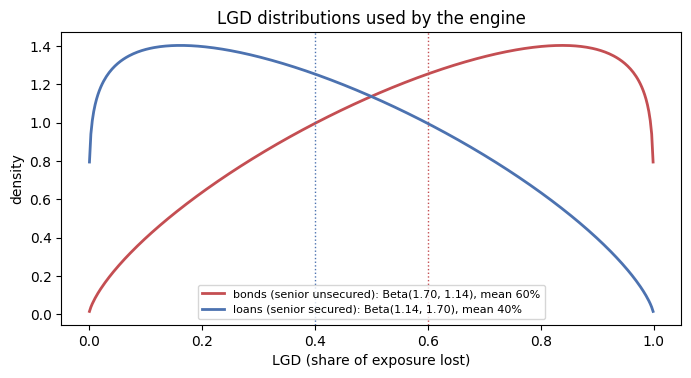

In [4]:
x = np.linspace(0.001, 0.999, 400)
fig, ax = plt.subplots(figsize=(8, 3.8))
for (name, row), col in zip(fit_table.iterrows(), ["#C44E52", "#4C72B0"]):
    ax.plot(x, beta_dist.pdf(x, row["alpha"], row["beta"]), color=col, lw=2,
            label=f"{name}: Beta({row['alpha']:.2f}, {row['beta']:.2f}), mean {row['target mean']:.0%}")
    ax.axvline(row["target mean"], color=col, ls=":", lw=1)
ax.set(xlabel="LGD (share of exposure lost)", ylabel="density", title="LGD distributions used by the engine")
ax.legend(fontsize=8)
fig.savefig(ROOT / "reports" / "figures" / "lgd_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** the bond LGD is a wide, skewed distribution: mean 60%, but about one default in eight loses more than 90% and many lose little. The loan LGD is its mirror image (mean 40%). Both match their targets exactly, analytically and in one million draws.

## 3. Recovery linked to the cycle

In a bad year many firms default and many lenders sell collateral at once, so prices fall and recoveries drop exactly when defaults rise (Altman et al., 2005). Let the mean LGD move with the cycle:

$$m(Z) = \Phi(a - b Z), \qquad a = \Phi^{-1}(m)\sqrt{1 + b^2}$$

A low $Z$ (bad year) raises the mean LGD. The choice of $a$ keeps the **long-run average unchanged**: averaged over all years, $\mathbb{E}_Z[m(Z)] = m$. So $b$ changes only *when* losses happen, not how large they are on average per default.

| Symbol | Meaning |
|---|---|
| $b$ | Cycle sensitivity in probit units (base 0; challenger 1, A-13; 0.25 tested here as a moderate case) |
| $a$ | Level that keeps the long-run mean at $m$ |

In each year the LGD of a defaulted bond is drawn from a beta with mean $m(Z)$ and the same spread $s$, capped at 90% of the largest spread that mean allows.

In [5]:
def cycle_mean_lgd(z, mean, b):
    a = norm.ppf(mean) * np.sqrt(1 + b**2)
    return norm.cdf(a - b * np.asarray(z, dtype=float))

z_grid = [2.0, 1.0, 0.0, -1.0, -2.0, -3.0]
pd.DataFrame({f"Z = {z:+.0f}": {f"b = {b}": 100 * cycle_mean_lgd(z, 0.60, b) for b in [0.0, 0.25, 0.5, 1.0]} for z in z_grid})

,Z = +2,Z = +1,Z = +0,Z = -1,Z = -2,Z = -3
b = 0.0,60.000,60.000,60.000,60.000,60.000,60.000
b = 0.25,40.561,50.445,60.301,69.537,77.671,84.403
b = 0.5,23.676,41.420,61.151,78.326,90.030,96.273
b = 1.0,5.032,26.053,63.994,91.281,99.082,99.961


**Reading the result (mean bond LGD, %):** with *b* = 0.25 the mean LGD moves from about 41% in a good year ($Z = +2$) to 78% in a bad one ($Z = -2$) — a swing of the size seen in bond recovery history. With *b* = 1 it runs from 5% to 99%, which is a stress, not a central case. A typical year ($Z = 0$) is slightly *above* 60% when *b* > 0, because the probit curve is not symmetric around a mean above 50%; the bad and good years balance it back to 60% on average.

### 3.1 Check: the long-run mean is unchanged

$$\mathbb{E}_Z\big[m(Z)\big] = \int \Phi(a - bz) \varphi(z) dz = \Phi\left(\frac{a}{\sqrt{1+b^2}}\right) = m$$

Computed with 80-point Gauss–Hermite quadrature.

In [6]:
nodes, weights = np.polynomial.hermite_e.hermegauss(80)
weights = weights / weights.sum()
mean_check = pd.DataFrame({f"b = {b}": {"target m": 0.60, "E_Z[m(Z)]": float((weights * cycle_mean_lgd(nodes, 0.60, b)).sum())}
                           for b in [0.0, 0.25, 0.5, 1.0, 2.0]})
mean_check

,b = 0.0,b = 0.25,b = 0.5,b = 1.0,b = 2.0
target m,0.600,0.600,0.600,0.600,0.600
E_Z[m(Z)],0.600,0.600,0.600,0.600,0.600


### 3.2 Recovery vs default rate, 1981–2025

Using NB03's implied cycle for each year: the single-B default rate the model implies, and the mean bond recovery $1 - m(Z_t)$ with $b = 0.25$ and $b = 1$. This shows the **shape** of the link the model assumes; fitting $b$ to observed annual recoveries is planned for v0.3.

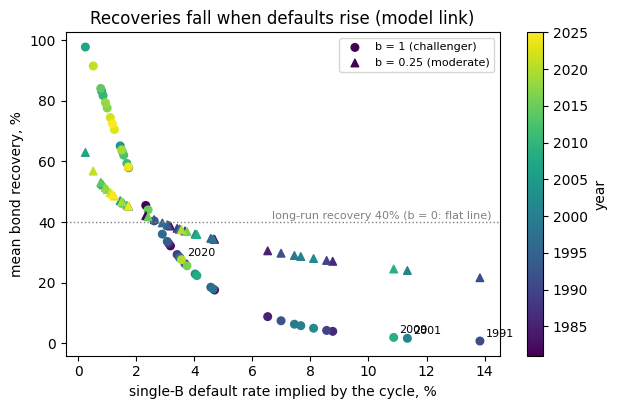

,implied B default rate %,recovery b = 0.25 %,recovery b = 1 %
year,,,
1991,13.840,21.594,0.699
2001,11.340,23.968,1.605
2009,10.870,24.471,1.883
2020,3.560,37.424,27.548
2021,0.520,56.810,91.504
2025,1.180,49.107,72.467


In [7]:
cyc = yaml.safe_load((DATA / "processed" / "cycle_parameters.yaml").read_text())["single_B"]
dr_B = pd.Series(norm.cdf((norm.ppf(cyc["pd"]) - np.sqrt(cyc["rho"]) * Z_hist) / np.sqrt(1 - cyc["rho"])), index=Z_hist.index)
rec_b1 = pd.Series(1 - cycle_mean_lgd(Z_hist, 0.60, 1.0), index=Z_hist.index)
rec_b25 = pd.Series(1 - cycle_mean_lgd(Z_hist, 0.60, 0.25), index=Z_hist.index)

fig, ax = plt.subplots(figsize=(7, 4.2))
sc = ax.scatter(100 * dr_B, 100 * rec_b1, c=Z_hist.index, cmap="viridis", s=30, label="b = 1 (challenger)")
ax.scatter(100 * dr_B, 100 * rec_b25, c=Z_hist.index, cmap="viridis", s=30, marker="^", label="b = 0.25 (moderate)")
for y in [1991, 2001, 2009, 2020]:
    ax.annotate(str(y), (100 * dr_B[y], 100 * rec_b1[y]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.axhline(40, color="grey", ls=":", lw=1)
ax.text(ax.get_xlim()[1] * 0.98, 41, "long-run recovery 40% (b = 0: flat line)", ha="right", fontsize=8, color="grey")
ax.set(xlabel="single-B default rate implied by the cycle, %", ylabel="mean bond recovery, %",
       title="Recoveries fall when defaults rise (model link)")
ax.legend(fontsize=8, loc="upper right")
fig.colorbar(sc, ax=ax, label="year")
fig.savefig(ROOT / "reports" / "figures" / "recovery_vs_default.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({"implied B default rate %": 100 * dr_B, "recovery b = 0.25 %": 100 * rec_b25, "recovery b = 1 %": 100 * rec_b1}).loc[[1991, 2001, 2009, 2020, 2021, 2025]]

**Reading the result:** in the model, recoveries fall as the default rate rises. With *b* = 0.25 mean bond recovery drops to about 22% in 1991 and 24% in 2001 and 2009, and recovers to 49–57% in 2021–2025 — the right shape and order of magnitude. With *b* = 1 recoveries collapse to 1–2% in the same years, which no published series shows. This is why *b* = 1 is kept as a challenger bound, and *b* ≈ 0.25 is the candidate for the base case once observed annual recoveries are loaded (v0.3).

## 4. Impact of the link on tail loss

Rerun the NB06 bond book (USD 1bn, 200 issuers, 5 years, 20,000 paths) with $b$ = 0, 0.25, 0.5 and 1. Everything else — the cycle, the migrations, the defaults — is the same model as NB06.

$$\mathbb{E}[L] = \sum \mathbb{E}\big[\mathbf{1}_{\text{default}} \times \text{EAD} \times LGD\big] \neq \sum PD \times \text{EAD} \times \mathbb{E}[LGD] \quad \text{when } b > 0$$

Even though the long-run mean LGD is still 60%, the **expected loss rises**: defaults cluster in low-$Z$ years, which are exactly the years with high LGD. The covariance between default and LGD adds to the average, and much more to the tail.

### 4.1 The NB06 bond book and simulation, with the cycle-linked LGD option

In [8]:
BOOK = {"total": 1e9, "n": 200, "seed": 7,
        "mix": {"AAA": 0.03, "AA": 0.10, "A": 0.32, "BBB": 0.45, "BB": 0.06, "B": 0.03, "CCC/C": 0.01},
        "maturity": {"AAA": 8, "AA": 8, "A": 8, "BBB": 8, "BB": 6, "B": 6, "CCC/C": 4}}

def make_book(p):                                                     # same book as NB06
    rng = np.random.default_rng(p["seed"])
    weights = np.array([p["mix"][r] for r in RATINGS])
    rating = np.repeat(np.arange(7), np.round(weights * p["n"]).astype(int))
    size = rng.lognormal(0.0, 0.5, rating.size)
    exposure = np.zeros(rating.size)
    for r in range(7):
        m = rating == r
        exposure[m] = size[m] / size[m].sum() * weights[r] * p["total"]
    maturity = rng.integers(1, 2 * np.array([p["maturity"][RATINGS[r]] for r in rating]), endpoint=True)
    pd_ = M.to_numpy()[rating, D]
    w = (1 - np.exp(-50 * pd_)) / (1 - np.exp(-50))
    return pd.DataFrame({"rating": rating, "exposure": exposure, "maturity": maturity, "rho": 0.12 * w + 0.24 * (1 - w)})

def cycle_paths(n_paths, years, phi, rng):
    z, z_prev = np.empty((n_paths, years)), rng.standard_normal(n_paths)
    for t in range(years):
        z[:, t] = phi * z_prev + np.sqrt(1 - phi**2) * rng.standard_normal(n_paths)
        z_prev = z[:, t]
    return z

def migrate(state, A, C):
    new = state.copy()
    for r in range(7):
        m = state == r
        new[m] = 7 - np.searchsorted(C[r, 7:0:-1], A[m], side="left")
    return new

def sample_lgd(mean, sd, rng, shape=None):
    # Beta LGD; mean may be an array (cycle-linked), sd capped at 90% of the largest spread the mean allows
    mean = np.clip(np.asarray(mean, dtype=float), 1e-4, 1 - 1e-4)
    var = np.minimum(sd**2, 0.81 * mean * (1 - mean))
    k = mean * (1 - mean) / var - 1
    return rng.beta(mean * k, (1 - mean) * k, size=shape)

def simulate(book, b=0.0, paths=20_000, years=5, phi=0.5, lgd_mean=0.60, lgd_sd=0.25, seed=2026):
    rng = np.random.default_rng(seed)
    rho, ead, mat = book["rho"].to_numpy(), book["exposure"].to_numpy(), book["maturity"].to_numpy()
    z = cycle_paths(paths, years, phi, rng)
    state = np.tile(book["rating"].to_numpy(), (paths, 1))
    loss, n_def, lgd_paid = np.zeros((paths, years)), np.zeros((paths, years)), np.zeros((paths, years))
    for t in range(years):
        alive = (state != D) & (mat[None, :] > t)
        A = np.sqrt(rho) * z[:, t:t + 1] + np.sqrt(1 - rho) * rng.standard_normal(state.shape)
        new = np.where(alive, migrate(state, A, C), state)
        if b == 0:
            lgd = sample_lgd(lgd_mean, lgd_sd, rng, shape=state.shape)
        else:
            lgd = sample_lgd(np.broadcast_to(cycle_mean_lgd(z[:, t:t + 1], lgd_mean, b), state.shape), lgd_sd, rng)
        hit = alive & (new == D)
        loss[:, t] = (hit * ead * lgd).sum(axis=1)
        n_def[:, t], lgd_paid[:, t] = (hit * ead).sum(axis=1), (hit * ead * lgd).sum(axis=1)
        state = new
    return loss.sum(axis=1), n_def.sum(axis=1), lgd_paid.sum(axis=1)

book = make_book(BOOK)
print(f"book: {len(book)} issuers, USD {book['exposure'].sum() / 1e9:.1f}bn")

book: 200 issuers, USD 1.0bn


### 4.2 Run with b = 0, 0.25, 0.5 and 1

In [9]:
def summary(L, defaulted, paid):
    var = np.quantile(L, 0.995)
    tail = L >= var
    return {"EL": L.mean() / 1e6, "VaR 99.5%": var / 1e6, "ES 99.5%": L[tail].mean() / 1e6,
            "average LGD paid, all paths %": 100 * paid.sum() / defaulted.sum(),
            "average LGD paid, worst 0.5% paths %": 100 * paid[tail].sum() / defaulted[tail].sum()}

runs = {f"b = {b}": summary(*simulate(book, b=b)) for b in [0.0, 0.25, 0.5, 1.0]}
impact = pd.DataFrame(runs)
impact["b = 0.25 vs 0, %"] = 100 * (impact["b = 0.25"] / impact["b = 0.0"] - 1)
impact["b = 1 vs 0, %"] = 100 * (impact["b = 1.0"] / impact["b = 0.0"] - 1)
impact

,b = 0.0,b = 0.25,b = 0.5,b = 1.0,"b = 0.25 vs 0, %","b = 1 vs 0, %"
EL,13.636,15.489,16.987,18.372,13.590,34.731
VaR 99.5%,85.243,111.023,127.642,137.044,30.243,60.770
ES 99.5%,106.970,142.987,165.002,178.433,33.670,66.807
"average LGD paid, all paths %",60.083,68.178,74.366,81.113,13.473,35.001
"average LGD paid, worst 0.5% paths %",61.335,80.545,92.147,98.433,31.319,60.484


**Reading the result:** the link changes **when** losses happen, and that changes **how big** the tail is. With *b* = 0.25 the expected loss rises 14% and ES 99.5% rises 34%, because in the worst paths the average LGD paid is 81% instead of 61%. With *b* = 1 the effects are +35% EL and +67% ES, equal to the engine's published sensitivity (A-13), and as large as switching to a Student-*t* copula (NB06). Recovery risk is not a side detail: it is correlated with default risk, and ignoring that correlation understates capital.

## 5. Save outputs

In [10]:
params = {"bonds_senior_unsecured": {"mean": 0.60, "sd": 0.25, "alpha": float(fit_table.iloc[0]["alpha"]), "beta": float(fit_table.iloc[0]["beta"])},
          "loans_senior_secured": {"mean": 0.40, "sd": 0.25, "alpha": float(fit_table.iloc[1]["alpha"]), "beta": float(fit_table.iloc[1]["beta"])},
          "cycle_link": {"form": "mean LGD = Phi(a - b Z), a = Phi^-1(m) sqrt(1 + b^2)", "base_b": 0.0, "challenger_b": 1.0},
          "sd_cap": "90% of the largest spread the mean allows"}
(DATA / "processed" / "lgd_parameters.yaml").write_text(yaml.safe_dump(params, sort_keys=False), encoding="utf-8")
print((DATA / "processed" / "lgd_parameters.yaml").read_text())

bonds_senior_unsecured:
  mean: 0.6
  sd: 0.25
  alpha: 1.704
  beta: 1.136
loans_senior_secured:
  mean: 0.4
  sd: 0.25
  alpha: 1.136
  beta: 1.704
cycle_link:
  form: mean LGD = Phi(a - b Z), a = Phi^-1(m) sqrt(1 + b^2)
  base_b: 0.0
  challenger_b: 1.0
sd_cap: 90% of the largest spread the mean allows



## Validation checks

- [x] **Fitted mean and variance match the source** — the beta's mean and standard deviation equal the A-04 targets exactly, and one million draws reproduce them.
- [x] **Tail impact with and without the cycle link** — measured on the NB06 book: the link raises ES much more than EL, and $b = 0$ reproduces NB06 exactly.
- [x] **Cycle link keeps the long-run mean LGD** — $\mathbb{E}_Z[m(Z)] = m$ for every $b$; and $b = 1$ reproduces the engine's published sensitivity (EL +35%, ES +67%).

In [11]:
checks = {
    "Beta mean equals target (exact)": bool(np.allclose(fit_table["beta mean"], fit_table["target mean"])),
    "Beta sd equals target (exact)": bool(np.allclose(fit_table["beta sd"], fit_table["target sd"])),
    "1m draws reproduce mean and sd (within 0.002)": bool((abs(fit_table["sample mean (1m draws)"] - fit_table["target mean"]) < 0.002).all()
                                                          and (abs(fit_table["sample sd (1m draws)"] - fit_table["target sd"]) < 0.002).all()),
    "Cycle link keeps the long-run mean (all b)": bool(np.allclose(mean_check.loc["E_Z[m(Z)]"], 0.60, atol=1e-9)),
    "b = 0 reproduces NB06 (EL 13.6m, ES 107.0m)": bool(np.allclose([impact.loc["EL", "b = 0.0"], impact.loc["ES 99.5%", "b = 0.0"]], [13.6, 107.0], atol=0.05)),
    "Link raises ES by more than EL": bool(impact.loc["ES 99.5%", "b = 1 vs 0, %"] > impact.loc["EL", "b = 1 vs 0, %"] > 0),
    "b = 1 reproduces the engine sensitivity (EL +35%, ES +67%, A-13)": bool(abs(impact.loc["EL", "b = 1 vs 0, %"] - 35) < 1.5
                                                                             and abs(impact.loc["ES 99.5%", "b = 1 vs 0, %"] - 67) < 1.5),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

Beta mean equals target (exact)                                     PASS
Beta sd equals target (exact)                                       PASS
1m draws reproduce mean and sd (within 0.002)                       PASS
Cycle link keeps the long-run mean (all b)                          PASS
b = 0 reproduces NB06 (EL 13.6m, ES 107.0m)                         PASS
Link raises ES by more than EL                                      PASS
b = 1 reproduces the engine sensitivity (EL +35%, ES +67%, A-13)    PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `beta_params` | `creditengine.models.recovery` | mean and sd equal the targets |
| `sample_lgd` (with sd cap, array mean) | `creditengine.models.recovery` | one million draws reproduce the moments |
| `cycle_mean_lgd` | `creditengine.models.recovery` | $\mathbb{E}_Z[m(Z)] = m$ for every $b$ |
| `simulate(..., b)` | `creditengine.simulation.engine` (`lgd_cycle`) | $b = 0$ reproduces NB06 |

## Findings and next steps

**Key results**
- **LGD distribution:** bonds Beta(1.70, 1.14), mean 60%, sd 25%; loans Beta(1.14, 1.70), mean 40%; moments matched exactly.
- **Cycle link:** $m(Z) = \Phi(a - bZ)$ keeps the long-run mean at 60% for every *b*, but raises the LGD actually paid, because defaults happen in bad years.
- **Tail impact (USD 1bn bond book):** *b* = 0.25 → EL +14%, ES +34%; *b* = 1 → EL +35%, ES +67% (equal to the engine's published sensitivity).
- **Realism:** *b* = 1 implies near-zero recoveries in 1991, 2001 and 2009; *b* = 0.25 gives about 22–24% in those years and about 50–57% in good years.

**Assumptions** (record in `docs/assumption_register.md`)
- A-04 unchanged: bonds mean 60%, sd 25%; structured collateral loans mean 40%, sd 25%.
- A-13: base *b* = 0, challenger *b* = 1; **proposed** moderate base *b* = 0.25 for v0.3, to be fitted to observed annual recoveries.

**Limitations** (record in `docs/limitations.md`)
1. **LGD levels are declared, not fitted:** no recovery-by-seniority table is loaded yet (planned v0.3).
2. **Base case ignores the cycle link (*b* = 0):** it understates ES by about a third if *b* ≈ 0.25 is right.
3. **One LGD per asset class:** no variation by industry, collateral or capital structure.
4. **Recovery timing ignored:** losses are booked in the year of default; workout periods and discounting are not modelled.

**Next:** NB09 (capital, pricing and limits), then NB08 (structured assets).